# Spatial analysis of the 2026 Alberta referendum, question 10
Joseph and Zarif. Adapted from a collaborator's Colab notebook; the script version is `scripts/06-spatial_analysis.py`.

**Read before citing.** Locations are *approximate riding centres*, not boundaries, so Moran's I and the neighbour weights are provisional until the Elections Alberta boundary file is used. There is no regression: the original notebook's covariates were randomly generated and were removed. Votes come from `data/02-analysis_data/ed_results_2026.csv`.

Run from the project root's `notebooks/` folder with the project virtual environment.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import ANALYSIS, EXPECTED_2026, RAW

K_NEIGHBOURS = 5
N_PERMUTATIONS = 9999
SEED = 42
REGION_COLOURS = {"Edmonton": "#4575b4", "Calgary": "#74add1", "Central": "#fdae61",
                  "North": "#f46d43", "South": "#d73027"}
LISA_COLOURS = {"High-High": "#d73027", "Low-Low": "#4575b4",
                "High-Low": "#fdae61", "Low-High": "#abd9e9"}

## 1. Load question 10 and riding locations
Option 2 is the second choice on the ballot. The assertions tie the data to the published provincial totals.

In [2]:
results = pd.read_csv(ANALYSIS / "ed_results_2026.csv", dtype={"ed_code": str})
q10 = results[results["question_number"] == 10].copy()
q10["total"] = q10["choice_1_votes"] + q10["choice_2_votes"]
q10["option2_pct"] = 100 * q10["choice_2_votes"] / q10["total"]

centroids = pd.read_csv(RAW / "riding_centroids.csv", dtype={"ed_code": str})
df = q10.merge(centroids[["ed_code", "region", "lat", "lon"]], on="ed_code", how="left")

assert len(df) == 87 and df["lat"].notna().all()
assert df["choice_1_votes"].sum() == EXPECTED_2026[10]["choice_1"]
assert df["choice_2_votes"].sum() == EXPECTED_2026[10]["choice_2"]

y = df["option2_pct"].to_numpy()
print(f"Option 2 share, provincial: {100 * df['choice_2_votes'].sum() / df['total'].sum():.2f}%")
print(f"Divisions above 50%: {(y > 50).sum()}")
df.loc[y > 50, ["ed_name", "option2_pct"]]

Option 2 share, provincial: 25.05%
Divisions above 50%: 2


,ed_name,option2_pct
54,CENTRAL PEACE-NOTLEY,50.459921
79,RIMBEY-ROCKY MOUNTAIN HOUSE-SUNDRE,50.937487


## 2. Map of the vote
Points sit at approximate riding centres and are sized by electors.

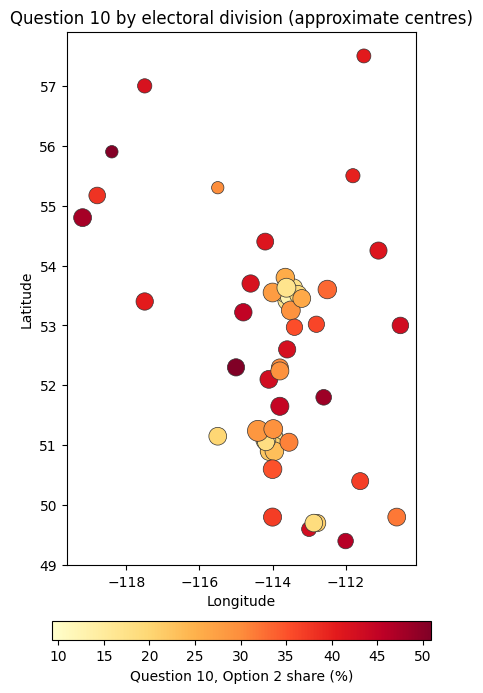

In [3]:
fig, ax = plt.subplots(figsize=(7, 9))
sc = ax.scatter(df["lon"], df["lat"], c=df["option2_pct"], cmap="YlOrRd",
                s=df["electors"] / 250, edgecolor="#333333", linewidth=0.5)
fig.colorbar(sc, ax=ax, orientation="horizontal", shrink=0.7, pad=0.08,
             label="Question 10, Option 2 share (%)")
ax.set_title("Question 10 by electoral division (approximate centres)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.radians(df["lat"].mean())))
plt.show()

## 3. Spatial weights and Global Moran's I
Row-standardised k-nearest-neighbour weights, with longitude scaled by cos(latitude). The p-value comes from permuting the values across divisions.

In [4]:
def knn_weights(coords, k):
    scaled = coords.copy()
    scaled[:, 0] *= np.cos(np.radians(coords[:, 1].mean()))
    d = np.linalg.norm(scaled[:, None, :] - scaled[None, :, :], axis=2)
    np.fill_diagonal(d, np.inf)
    w = np.zeros_like(d)
    for i, cols in enumerate(np.argsort(d, axis=1)[:, :k]):
        w[i, cols] = 1.0
    return w / w.sum(axis=1, keepdims=True)

def morans_i(values, w):
    dev = values - values.mean()
    return (len(values) / w.sum()) * (dev @ w @ dev) / (dev @ dev)

coords = df[["lon", "lat"]].to_numpy()
W = knn_weights(coords, K_NEIGHBOURS)

rng = np.random.default_rng(SEED)
i_obs = morans_i(y, W)
i_perm = np.array([morans_i(rng.permutation(y), W) for _ in range(N_PERMUTATIONS)])
p_value = (1 + np.sum(i_perm >= i_obs)) / (N_PERMUTATIONS + 1)
print(f"Global Moran's I (k={K_NEIGHBOURS}): {i_obs:.4f}, pseudo p = {p_value:.4f}")
pd.Series({k: morans_i(y, knn_weights(coords, k)) for k in (3, 5, 7, 10)}, name="Moran's I").rename_axis("k").round(4).to_frame()

Global Moran's I (k=5): 0.6496, pseudo p = 0.0001


,Moran's I
k,
3,0.6797
5,0.6496
7,0.6013
10,0.4888


## 4. LISA quadrants
Descriptive only: no local significance test, so a quadrant label is not evidence of a real cluster.

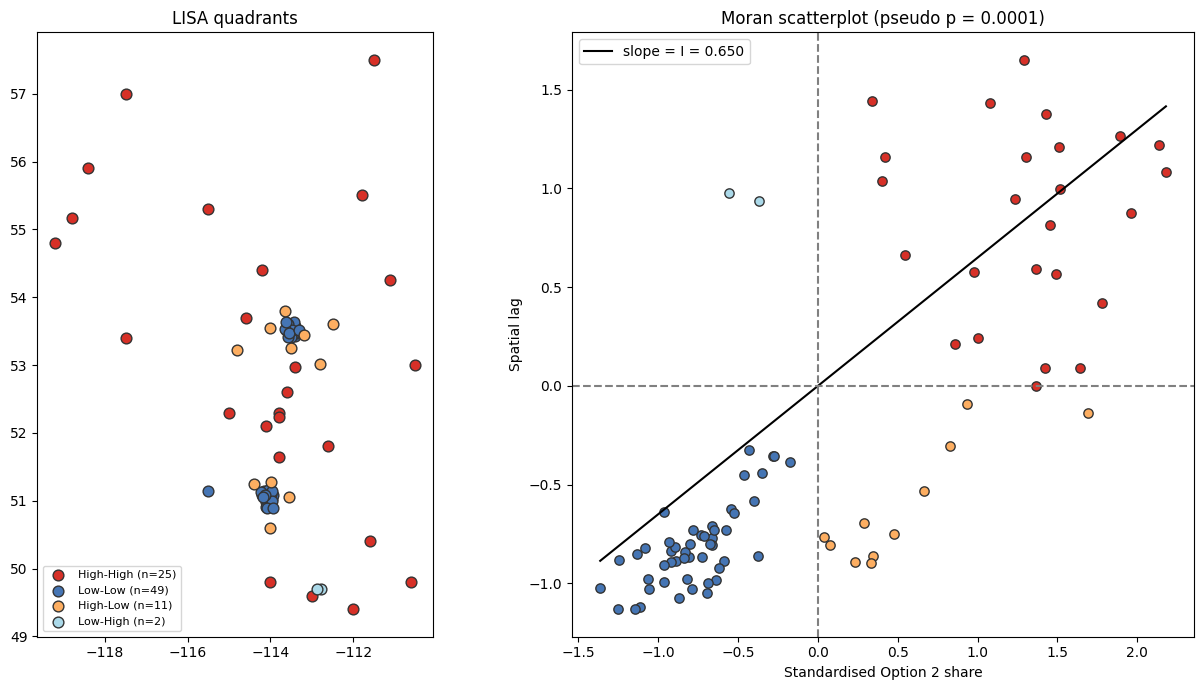

lisa
Low-Low      49
High-High    25
High-Low     11
Low-High      2
Name: count, dtype: int64

In [5]:
z = (y - y.mean()) / y.std()
lag = W @ z
df["z"], df["lag"] = z, lag
df["lisa"] = np.select(
    [(z > 0) & (lag > 0), (z < 0) & (lag < 0), (z > 0) & (lag < 0)],
    ["High-High", "Low-Low", "High-Low"], default="Low-High")

fig, (ax_map, ax_sc) = plt.subplots(1, 2, figsize=(13, 7))
for name, colour in LISA_COLOURS.items():
    sub = df[df["lisa"] == name]
    ax_map.scatter(sub["lon"], sub["lat"], c=colour, s=60, edgecolor="#333333",
                   label=f"{name} (n={len(sub)})")
    ax_sc.scatter(sub["z"], sub["lag"], c=colour, s=45, edgecolor="#333333")
ax_map.legend(loc="lower left", fontsize=8)
ax_map.set_title("LISA quadrants")
ax_map.set_aspect(1 / np.cos(np.radians(df["lat"].mean())))
xs = np.linspace(z.min(), z.max(), 20)
ax_sc.plot(xs, i_obs * xs, color="black", label=f"slope = I = {i_obs:.3f}")
ax_sc.axhline(0, color="grey", linestyle="--"); ax_sc.axvline(0, color="grey", linestyle="--")
ax_sc.set_xlabel("Standardised Option 2 share"); ax_sc.set_ylabel("Spatial lag")
ax_sc.set_title(f"Moran scatterplot (pseudo p = {p_value:.4f})")
ax_sc.legend()
plt.tight_layout(); plt.show()
df["lisa"].value_counts()

## 5. Regional comparison

,n,median,mean,min,max
region,,,,,
Calgary,26,17.51,17.41,10.68,23.27
Central,22,32.04,34.47,16.81,50.94
Edmonton,20,14.80,14.50,9.28,17.99
North,10,41.01,41.18,30.04,50.46
South,9,35.02,32.15,18.78,46.20


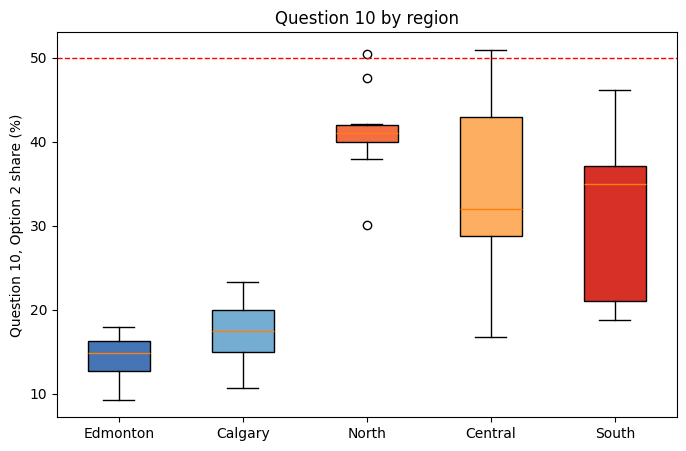

In [6]:
summary = (df.groupby("region")["option2_pct"]
           .agg(n="count", median="median", mean="mean", min="min", max="max").round(2))
display(summary)

order = ["Edmonton", "Calgary", "North", "Central", "South"]
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([df.loc[df["region"] == r, "option2_pct"] for r in order],
                tick_labels=order, patch_artist=True)
for patch, r in zip(bp["boxes"], order):
    patch.set_facecolor(REGION_COLOURS[r])
ax.axhline(50, color="red", linestyle="--", linewidth=1)
ax.set_ylabel("Question 10, Option 2 share (%)"); ax.set_title("Question 10 by region")
plt.show()

## Next steps
- Replace approximate centres with the Elections Alberta boundary file, then recompute weights (queen contiguity) and Moran's I.
- Add a local significance test for LISA.
- Add real covariates (for example Statistics Canada indicators, 2023 election results) before any spatial lag model.